# 04 · Behavioural features: what predicts *reacting* to the SMS?

40 features are computed in DuckDB from the 45.8M-row purchase log (`src/uplift/features.py`, ~30 s), strictly before the
campaign start, in five groups:

| Group | Examples |
|---|---|
| frequency | purchases in the last 7/14/30/60 days, gaps between purchases, "overdue" ratio, 30-day trend |
| monetary | spend in the last 7/30 days, basket mean/std/max, basket trend |
| loyalty_points | points received/spent, share of spend paid with points, **express (promo) points** used |
| basket_content | items per basket, product variety, own-brand and alcohol share, top-category shares |
| habits | weekend/morning/evening share, mean hour, number of stores, favourite-store share |

The question is not "which features predict purchases" but **which features predict how much the SMS changes
purchases**. These are different things, and confusing them is the reason response models fail (notebook 03).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from uplift.features import FEATURE_GROUPS, load_model_table
from uplift.metrics import cv_evaluate
from uplift.models import (BASE_SPEC, CLIENT_SPEC, FULL_SPEC, ClassTransformation, TLearner,
                           UpliftScreened, group_spec, spec_for, uplift_signal)

FIG = ROOT / "reports" / "figures"
df = load_model_table()
train = df[df.split == "train"]
pool = df[df.split != "test"].reset_index(drop=True)   # train + valid for cross-validation; test stays untouched
print(f"{len(FULL_SPEC.columns)} model features; train {len(train):,}; CV pool {len(pool):,}")

49 model features; train 120,023; CV pool 160,031


## 1. Purchase signal vs uplift signal

For every feature, on the training split only:
* **x-axis:** Spearman correlation with *buying* (what a response model learns),
* **y-axis:** z-statistic of the correlation with the *transformed outcome* Z = y·(t/p − (1−t)/(1−p)),
  whose expectation is the individual uplift. |z| > 2 means the effect really changes along the feature.

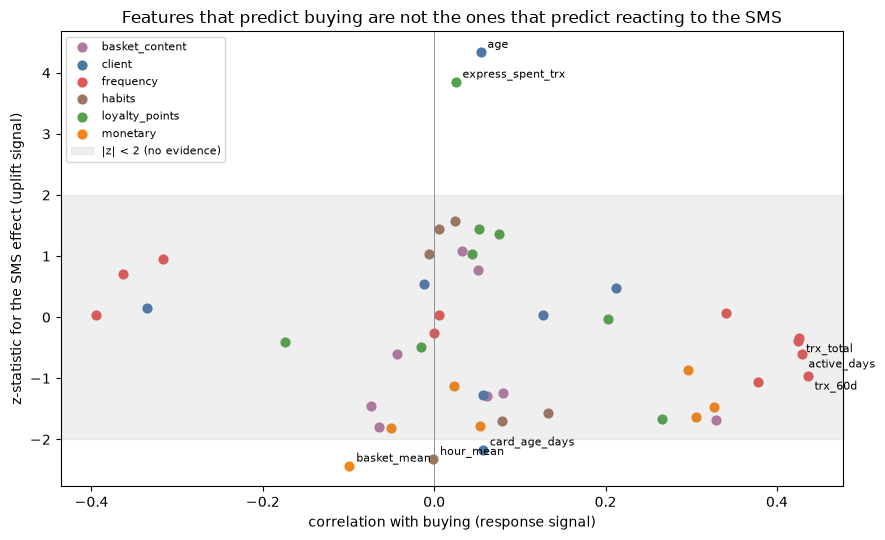

z_uplift  rho_response
                          feature                                  
strongest uplift signal   age                   4.341         0.054
                          express_spent_trx     3.853         0.025
                          basket_mean          -2.433        -0.099
                          hour_mean            -2.323        -0.001
                          card_age_days        -2.169         0.057
                          basket_std           -1.813        -0.050
                          products_per_trx     -1.792        -0.064
                          basket_max           -1.781         0.053
strongest purchase signal trx_60d              -0.959         0.436
                          active_days          -0.597         0.429
                          trx_total            -0.347         0.426
                          trx_30d              -0.389         0.424
                          gap_mean              0.035        -0.394
                          trx_14d              -1.069         0.378
                          gap_std               0.707        -0.363
                          trx_7d                0.064         0.340

In [2]:
numeric = [c for c in dict.fromkeys(FULL_SPEC.columns + BASE_SPEC.columns)
           if c not in ("gender",) and c not in ("n_transactions", "total_spend", "avg_basket",
                                                 "avg_items", "points_received", "points_spent")]
sig = uplift_signal(train, train.treatment_flg, train.target, numeric)
group_of = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
sig["group"] = [group_of.get(f, "client") for f in sig.index]

palette = {"client": "#4C78A8", "frequency": "#E45756", "monetary": "#F58518",
           "loyalty_points": "#54A24B", "basket_content": "#B279A2", "habits": "#9D755D"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for g, s in sig.groupby("group"):
    ax.scatter(s.rho_response, s.z_uplift, label=g, color=palette[g], s=40)
for f, r in sig[sig.z_uplift.abs() >= 2].iterrows():
    ax.annotate(f, (r.rho_response, r.z_uplift), xytext=(5, 3), textcoords="offset points", fontsize=8)
for f, r in sig.nlargest(3, "rho_response").iterrows():
    ax.annotate(f, (r.rho_response, r.z_uplift), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.axhspan(-2, 2, color="grey", alpha=0.12, label="|z| < 2 (no evidence)")
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("correlation with buying (response signal)")
ax.set_ylabel("z-statistic for the SMS effect (uplift signal)")
ax.set_title("Features that predict buying are not the ones that predict reacting to the SMS")
ax.legend(fontsize=8, loc="upper left"); fig.tight_layout()
fig.savefig(FIG / "04_response_vs_uplift_signal.png", dpi=150); plt.show()

pd.concat({"strongest uplift signal": sig.reindex(sig.z_uplift.abs().sort_values(ascending=False).index).head(8)[["z_uplift", "rho_response"]],
           "strongest purchase signal": sig.sort_values("rho_response", key=abs, ascending=False).head(8)[["z_uplift", "rho_response"]]}).round(3)

Frequency and spend features correlate with buying at 0.3–0.45 but carry **no evidence** of a different SMS
effect. The uplift signal sits in a few other places: age, using **express (promo) points**, and **smaller
baskets**. Two of them, checked directly as treatment-vs-control differences on the train+valid pool:

In [3]:
def effect(g):
    t, y = g.treatment_flg, g.target
    p1, p0 = y[t == 1].mean(), y[t == 0].mean()
    se = np.sqrt(p1 * (1 - p1) / (t == 1).sum() + p0 * (1 - p0) / (t == 0).sum())
    return pd.Series({"clients": len(g), "rate_without_sms": p0, "effect_pp": (p1 - p0) * 100,
                      "ci_low": (p1 - p0 - 1.96 * se) * 100, "ci_high": (p1 - p0 + 1.96 * se) * 100})

pool_ = pool.assign(
    promo_points_user=np.where(pool.express_spent_trx > 0, "used express points", "never"),
    basket_quartile=pd.qcut(pool.basket_mean, 4, labels=["Q1 smallest", "Q2", "Q3", "Q4 largest"]))
pd.concat({
    "express points": pool_.groupby("promo_points_user").apply(effect, include_groups=False),
    "basket size": pool_.groupby("basket_quartile", observed=True).apply(effect, include_groups=False),
}).round(2)

clients  rate_without_sms  effect_pp  \
express points never                130981.0              0.60       2.66   
               used express points   29050.0              0.61       6.31   
basket size    Q1 smallest           40008.0              0.65       5.26   
               Q2                    40008.0              0.64       2.92   
               Q3                    40007.0              0.59       2.56   
               Q4 largest            40008.0              0.54       2.64   

                                    ci_low  ci_high  
express points never                  2.14     3.19  
               used express points    5.21     7.41  
basket size    Q1 smallest            4.34     6.18  
               Q2                     1.98     3.85  
               Q3                     1.60     3.52  
               Q4 largest             1.66     3.61

## 2. Do the new features improve targeting? 5-fold cross-validation

A single 40k validation split gives Qini intervals as wide as the differences between configurations, so choices are
made on 5-fold CV over the 160k train+valid clients (the same folds for every configuration, so differences are
paired). Feature screening (`UpliftScreened`) runs *inside* each training fold.

In [4]:
configs = {"step-2 base table": BASE_SPEC, "client attributes only": CLIENT_SPEC}
configs.update({f"client + {g}": spec_for([g]) for g in FEATURE_GROUPS})
configs["client + all 40 features"] = FULL_SPEC
configs["step-2 base + loyalty_points"] = BASE_SPEC + group_spec("loyalty_points")

rows, folds = [], {}
for model in (TLearner, ClassTransformation):
    for name, spec in configs.items():
        r = cv_evaluate(pool, lambda: model(spec=spec))
        folds[(model.name, name)] = r.qini.to_numpy()
        rows.append((model.name, name, r.qini.mean() * 1000, r["uplift@10%"].mean() * 100, r["uplift@30%"].mean() * 100))
    r = cv_evaluate(pool, lambda: UpliftScreened(inner=model, threshold=1.5))
    folds[(model.name, "client + uplift-screened features")] = r.qini.to_numpy()
    rows.append((model.name, "client + uplift-screened features", r.qini.mean() * 1000,
                 r["uplift@10%"].mean() * 100, r["uplift@30%"].mean() * 100))

cv = pd.DataFrame(rows, columns=["model", "features", "Qini ×1000", "uplift@10% pp", "uplift@30% pp"]).set_index(["model", "features"])
t_crit = stats.t.ppf(0.975, df=4)
for key in cv.index:
    d = (folds[key] - folds[(key[0], "step-2 base table")]) * 1000
    cv.loc[key, "Δ Qini vs step-2 (95% CI)"] = f"{d.mean():+.2f} [{d.mean() - t_crit * d.std(ddof=1) / np.sqrt(5):+.2f}, {d.mean() + t_crit * d.std(ddof=1) / np.sqrt(5):+.2f}]"
cv.round(2)

Qini ×1000  \
model                features                                        
T-learner            step-2 base table                        3.39   
                     client attributes only                   2.71   
                     client + frequency                       2.90   
                     client + monetary                        3.33   
                     client + loyalty_points                  3.14   
                     client + basket_content                  3.19   
                     client + habits                          2.77   
                     client + all 40 features                 2.99   
                     step-2 base + loyalty_points             3.33   
                     client + uplift-screened features        3.26   
class transformation step-2 base table                        3.35   
                     client attributes only                   2.82   
                     client + frequency                       2.99   
                     client + monetary                        3.34   
                     client + loyalty_points                  3.34   
                     client + basket_content                  3.11   
                     client + habits                          2.84   
                     client + all 40 features                 3.07   
                     step-2 base + loyalty_points             3.40   
                     client + uplift-screened features        3.28   

                                                        uplift@10% pp  \
model                features                                           
T-learner            step-2 base table                          10.40   
                     client attributes only                      7.79   
                     client + frequency                          8.88   
                     client + monetary                          10.15   
                     client + loyalty_points                    10.42   
                     client + basket_content                     9.02   
                     client + habits                             7.64   
                     client + all 40 features                   11.61   
                     step-2 base + loyalty_points               10.63   
                     client + uplift-screened features          10.81   
class transformation step-2 base table                           9.64   
                     client attributes only                      7.50   
                     client + frequency                          8.06   
                     client + monetary                           9.69   
                     client + loyalty_points                    10.12   
                     client + basket_content                     8.83   
                     client + habits                             8.52   
                     client + all 40 features                   10.17   
                     step-2 base + loyalty_points               10.35   
                     client + uplift-screened features          10.94   

                                                        uplift@30% pp  \
model                features                                           
T-learner            step-2 base table                           6.75   
                     client attributes only                      5.87   
                     client + frequency                          5.84   
                     client + monetary                           6.81   
                     client + loyalty_points                     6.58   
                     client + basket_content                     6.44   
                     client + habits                             5.93   
                     client + all 40 features                    6.13   
                     step-2 base + loyalty_points                6.58   
                     client + uplift-screened features           6.52   
class transformation step-2 base

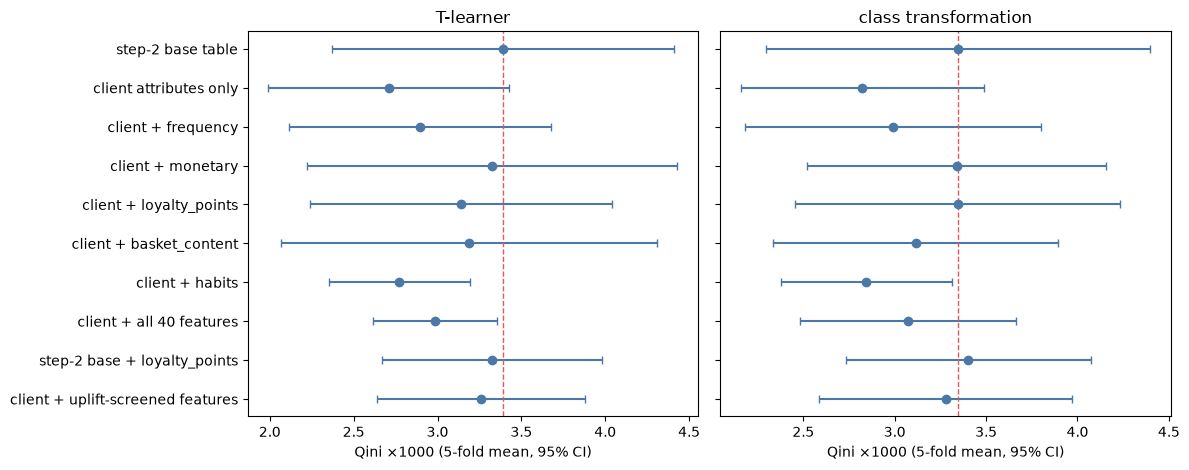

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, model in zip(axes, ["T-learner", "class transformation"]):
    names = [n for (m, n) in folds if m == model]
    means = [folds[(model, n)].mean() * 1000 for n in names]
    errs = [t_crit * folds[(model, n)].std(ddof=1) / np.sqrt(5) * 1000 for n in names]
    y = np.arange(len(names))[::-1]
    ax.errorbar(means, y, xerr=errs, fmt="o", color="#4C78A8", capsize=3)
    ax.axvline(folds[(model, "step-2 base table")].mean() * 1000, color="#E45756", ls="--", lw=1)
    ax.set_title(model); ax.set_xlabel("Qini ×1000 (5-fold mean, 95% CI)")
axes[0].set_yticks(y, names)
fig.tight_layout(); fig.savefig(FIG / "04_cv_feature_sets.png", dpi=150); plt.show()

## Conclusions

* **More features did not mean better targeting.** All 40 behavioural features together do not beat the small step-2
  table (Δ Qini −0.40 for the T-learner, CI includes 0), and adding only the frequency group makes it significantly
  worse. Frequency and spend features describe *who buys*; with a +3.3 pp average effect the extra dimensions mostly
  add noise to the uplift estimate.
* **The uplift signal is low-dimensional and interpretable:** older clients, clients who have used promo (express)
  points (+6.3 pp vs +2.7 pp) and clients in the smallest-basket quartile (+5.3 pp vs ~+2.6 pp) react more to the SMS.
* Adding the monetary or loyalty-points groups to client attributes recovers the step-2 level; uplift-aware screening
  inside the folds lands in the same place. The best configurations differ by less than their fold-to-fold noise, so
  the simpler one is preferred.
* **Decision for step 5:** keep the step-2 base table, optionally with the loyalty-points group, and spend the effort
  on learners that model *heterogeneity* directly (X-learner, causal forest, regularisation) rather than on more
  features.